# Gasto en I+D de las empresas y productividad por hora

In [ ]:
# Parámetros de la gráfica
SLUG = "economia"  # carpeta en research/temas/
GRAFICA_ID = "gasto-idi-empresas-productividad"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Gasto en I+D de las empresas y productividad por hora"  # `titulo` de la gráfica en config.json
DESDE = 1976  # primer año candidato (METODOLOGIA §2.3)
UNIVERSO = "ocde"  # ocde | ue27: todos sus países con dato en los dos ejes (METODOLOGIA §2.6)
EJE_X = {"titulo": "Gasto de las empresas en I+D", "unidad": "% del PIB"}
EJE_Y = {"titulo": "PIB por hora trabajada", "unidad": "dólares PPA por hora, precios corrientes"}
ANIOS = None  # (desde, hasta) si el config fija una ventana; None = último año común de cada país
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

Cada punto es un país de la OCDE con dato en los dos ejes.

- **Eje horizontal:** el **gasto de las empresas en investigación y desarrollo (I+D)** en porcentaje del PIB, con independencia de quién lo financie (lo que las empresas gastan en I+D, incluida la parte que reciben del sector público).
- **Eje vertical:** el **PIB por hora trabajada**, en dólares con la misma capacidad de compra en todos los países (PPA) a precios corrientes, una medida de la productividad del trabajo.

**Para qué sirve.** Es el contexto de las medidas que incentivan la I+D de las empresas, como la deducción por I+D+i en el Impuesto sobre Sociedades: muestra cuánto invierten las empresas de cada país en I+D y la productividad que alcanzan, el argumento de quienes sostienen que ese gasto la eleva. Quienes cuestionan esas medidas señalan que la productividad depende de otros factores (el capital, la formación, el tamaño de las empresas o su especialización) y que parte del gasto sustituye al que las empresas harían de todos modos. **La relación entre dos indicadores no muestra que uno cause el otro**: no se dibuja línea de tendencia ni se calcula la correlación.

**Limitaciones.**
- El gasto en I+D de las empresas incluye la parte financiada con fondos públicos y depende de la composición sectorial de cada economía: más industria y tecnología, más I+D.
- La productividad también depende de cuántas horas se trabajan y de quién trabaja (en los países con menos empleo juvenil o poco cualificado la productividad media es más alta).
- Cada punto usa el último año en que el país tiene dato en los dos ejes.

## 2. Descarga

- **OCDE, Main Science and Technology Indicators** (`OECD.STI.STP,DSD_MSTI@DF_MSTI`, versión 1.3): gasto interno en I+D del sector empresas (`B`, BERD) en % del PIB (`PT_B1GQ`); y la parte financiada por las propias empresas (`B_FB`), solo para las notas.
- **OCDE, base de datos de productividad** (`OECD.SDD.TPS,DSD_PDB@DF_PDB`, versión 2.0): PIB por hora trabajada (`GDPHRS`), total de actividades, en dólares PPA a precios corrientes (`USD_PPP_H`). El dataflow `DF_PDB_LV` que cita el config devuelve un error del servidor y se usa su sucesor `DF_PDB`.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.paises import paises_de
from lib.writer import construir_dispersion_data, write_dispersion_data

PAISES = paises_de(UNIVERSO)

from datetime import date

from lib import eurostat, oecd
from lib.paises import nombre_punto
from lib.tipos import FuenteMeta

AREAS = {c: c for c in PAISES}  # todos los países del universo, con su código como clave de serie
HOY = date.today().isoformat()

DATAFLOW_BERD = "OECD.STI.STP,DSD_MSTI@DF_MSTI,1.3"
# Dimensiones: país . frecuencia . medida . unidad . base de precios . transformación
CLAVE_BERD = "{AREA}.A.B.PT_B1GQ._Z._Z"  # BERD en % del PIB
DATAFLOW_PDB = "OECD.SDD.TPS,DSD_PDB@DF_PDB,2.0"
# Dimensiones: país . frecuencia . medida . actividad . unidad . base de precios . transformación . activo . conversión
CLAVE_PDB = "{AREA}.A.GDPHRS._T.USD_PPP_H.V.N._Z.PPP"  # PIB por hora trabajada, total de actividades

from lib.paises import NOMBRES_PAISES

# La productividad se pide de una vez para todos los países y las dos medias (la misma consulta que usa
# empleo-empresas-baja-productividad, con el universo de la UE-27) y aquí se filtran los de la OCDE
AREAS_PDB = {**{c: c for c in NOMBRES_PAISES}, "OECD": "OECD", "EU27_2020": "EU27_2020"}
medias = {"OECD": "OECD", "EU27_2020": "EU27_2020"}

x, _ = oecd.get(DATAFLOW_BERD, CLAVE_BERD, areas=AREAS, desde=DESDE)
y_todos, _ = oecd.get(DATAFLOW_PDB, CLAVE_PDB, areas=AREAS_PDB, desde=DESDE)
y = y_todos[y_todos["serie"].isin(AREAS)]
media_x, _ = oecd.get(DATAFLOW_BERD, CLAVE_BERD, areas=medias, desde=DESDE)
media_y = y_todos[y_todos["serie"].isin(medias)]
print("Países con gasto en I+D:", x["serie"].nunique(), "· con productividad:", y["serie"].nunique())
print("Medias de I+D:", sorted(media_x["serie"].unique()), "· de la productividad:", sorted(media_y["serie"].unique()))

Países con gasto en I+D: 38 · con productividad: 38
Medias de I+D: ['EU27_2020', 'OECD'] · de la productividad: ['EU27_2020', 'OECD']


## 3. Transformación

1. Los dos ejes se usan tal como los publica la OCDE, sin transformar.
2. **Puntos de las medias:** se añaden la media de la OCDE y la de la UE-27 si la OCDE las publica en los dos ejes (las dos fuentes son de la OCDE con las mismas definiciones de los agregados).
3. El escritor elige para cada país el último año con dato en los dos ejes, el mismo para `x` e `y`.
4. Para las notas: la parte del gasto en I+D de las empresas que financian las propias empresas.

In [ ]:
def unir(xs):
    xs = [str(x) for x in xs]
    return xs[0] if len(xs) == 1 else f"{', '.join(xs[:-1])} y {xs[-1]}"


def es(v, d=1):
    return estilos.formato_es(v, d)


# La media de cada agregado entra como un punto más solo si está en los dos ejes
comunes = sorted(set(media_x["serie"]) & set(media_y["serie"]))
x = pd.concat([x, media_x[media_x["serie"].isin(comunes)]], ignore_index=True)
y = pd.concat([y, media_y[media_y["serie"].isin(comunes)]], ignore_index=True)
print("Medias que son punto:", comunes)

# Parte del gasto en I+D de las empresas que financian las propias empresas (solo notas): B_FB, en % del BERD
fin, _ = oecd.get(DATAFLOW_BERD, "{AREA}.A.B_FB.PT_BERD._Z._Z", areas={"ESP": "ESP"}, desde=DESDE)
cuota = fin.set_index("periodo")["valor"]
a_comun = int(cuota.index.max())

_, FLUJO_BERD, VERSION_BERD = DATAFLOW_BERD.split(",")
_, FLUJO_PDB, VERSION_PDB = DATAFLOW_PDB.split(",")
fuentes = [
    FuenteMeta("eje_x", oecd.ORGANISMO, f"{FLUJO_BERD} (Main Science and Technology Indicators, versión {VERSION_BERD}): B (BERD), PT_B1GQ", oecd.URL_EXPLORER, HOY),
    FuenteMeta("eje_y", oecd.ORGANISMO, f"{FLUJO_PDB} (Productivity database, versión {VERSION_PDB}): GDPHRS, _T, USD_PPP_H, precios corrientes", oecd.URL_EXPLORER, HOY),
]
NOTAS = [
    f"Gasto de las empresas en I+D: OCDE, Main Science and Technology Indicators ({FLUJO_BERD}, versión {VERSION_BERD}): "
    "gasto interno en I+D del sector empresas (BERD) en porcentaje del PIB, incluida la parte financiada con fondos "
    "públicos y del exterior.",
    f"Productividad: OCDE, base de datos de productividad ({FLUJO_PDB}, versión {VERSION_PDB}): PIB por hora trabajada "
    "(total de actividades) en dólares estadounidenses PPA a precios corrientes del mismo año.",
    f"En España, las propias empresas financian el {es(cuota[a_comun])} % del gasto de las empresas en I+D en {a_comun}; "
    "el resto lo financian las administraciones públicas, el exterior y otras entidades (OCDE, "
    f"{FLUJO_BERD}, medida B_FB en porcentaje del BERD).",
    "El gasto en I+D depende de la composición sectorial de cada economía (más industria y tecnología, más I+D) y la "
    "productividad, de las horas trabajadas y de quién trabaja.",
]
if comunes:
    NOTAS.append(
        f"Medias: {unir(nombre_punto(c) for c in comunes)} como punto con su agregado de la OCDE en los dos ejes."
    )
else:
    NOTAS.append("Sin punto de la media OCDE ni de la UE-27: no están publicadas en los dos ejes.")

Medias que son punto: ['EU27_2020', 'OECD']


## 4. Visualización

Un punto por país, sin línea de tendencia ni correlación (METODOLOGIA §2.6).

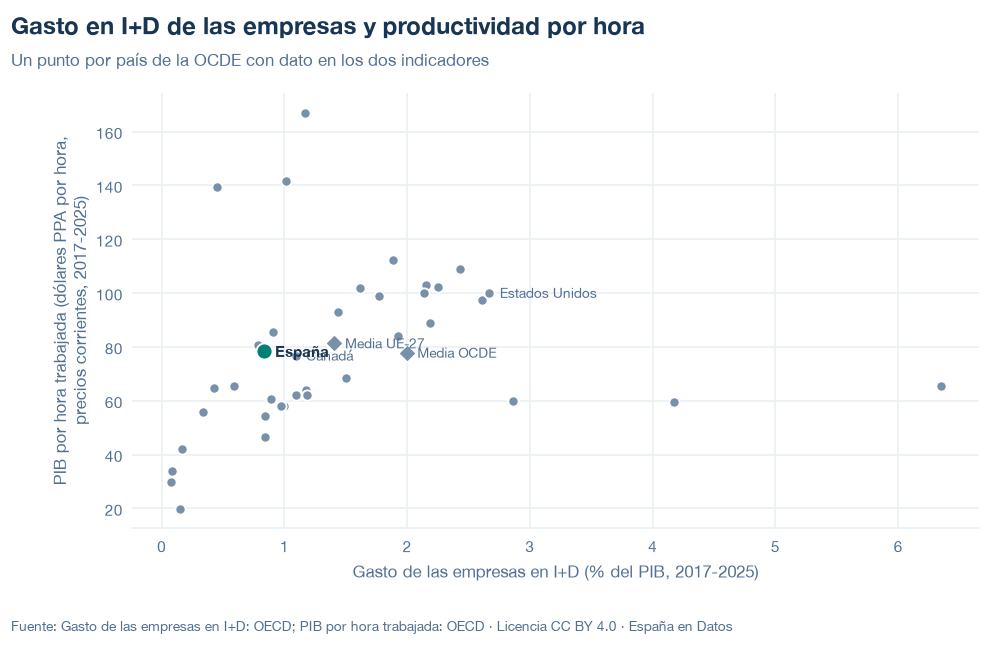

   codigo  anio        x          y
      AUS  2023 0.910831  85.576811
      AUT  2024 2.250519 102.417288
      BEL  2024 2.430001 108.925768
      CAN  2025 1.090562  76.813445
      CHE  2023 2.152754 103.011616
      CHL  2022 0.164776  41.980339
      COL  2020 0.149448  19.931954
      CRI  2024 0.084821  34.008622
      CZE  2024 1.179408  64.007870
      DEU  2024 2.136975  99.917275
      DNK  2024 1.885818 112.358084
      ESP  2024 0.836867  78.440076
      EST  2024 1.185080  62.189212
      FIN  2024 2.188027  88.712308
      FRA  2024 1.438603  93.117339
      GBR  2024 1.923935  84.195324
      GRC  2024 0.845449  46.658099
      HUN  2024 0.993273  57.950922
      IRL  2024 1.170866 167.075917
      ISL  2024 1.768421  99.079348
      ISR  2024 6.344755  65.594490
      ITA  2024 0.788625  80.654215
      JPN  2024 2.859108  59.915455
      KOR  2024 4.173046  59.447431
      LTU  2024 0.425233  64.682276
      LUX  2024 0.448283 139.565325
      LVA  2024 0.334535  55

In [ ]:
datos = construir_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
)
fig = estilos.figura(datos, titulo=TITULO)
estilos.mostrar(fig)
print(pd.DataFrame(datos["puntos"]).to_string(index=False))

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web (`codigo;pais;anio;eje_x;eje_y`).

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/gasto-idi-empresas-productividad.json y data/gasto-idi-empresas-productividad.csv


## 6. Fuentes, notas y licencia

- OCDE, Main Science and Technology Indicators: `OECD.STI.STP,DSD_MSTI@DF_MSTI,1.3` (`B`, `PT_B1GQ`; `B_FB`, solo notas).
- OCDE, base de datos de productividad: `OECD.SDD.TPS,DSD_PDB@DF_PDB,2.0` (`GDPHRS`, `_T`, `USD_PPP_H`, `V`, `N`, `_Z`, `PPP`).

La fecha de consulta de cada eje está en `fuentes` del JSON; las notas incluyen los países sin dato y la advertencia de que la relación no muestra causa.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.